### ***03. SK 유동인구 EDA 및 지역 비교***

In [25]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

folder = '/content/drive/MyDrive/bigcontest/data/sk_processed'

age_chuncheon = pd.read_csv(
    os.path.join(folder, 'flow_age_chuncheon_202507_202512.csv'),
    encoding='utf-8-sig'
)

age_gangnam = pd.read_csv(
    os.path.join(folder, 'flow_age_gangnam_202507_202512.csv'),
    encoding='utf-8-sig'
)

time_chuncheon = pd.read_csv(
    os.path.join(folder, 'flow_time_chuncheon_202507_202512.csv'),
    encoding='utf-8-sig'
)

time_gangnam = pd.read_csv(
    os.path.join(folder, 'flow_time_gangnam_202507_202512.csv'),
    encoding='utf-8-sig'
)

wkdy_chuncheon = pd.read_csv(
    os.path.join(folder, 'flow_wkdy_chuncheon_202507_202512.csv'),
    encoding='utf-8-sig'
)

wkdy_gangnam = pd.read_csv(
    os.path.join(folder, 'flow_wkdy_gangnam_202507_202512.csv'),
    encoding='utf-8-sig'
)

print("데이터 불러오기 완료!")

데이터 불러오기 완료!


In [27]:
# 코랩에서 한글 폰트 설치
!apt-get update -qq
!apt-get install -y fonts-nanum -qq

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 나눔고딕 적용
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
font = fm.FontProperties(fname=font_path)

plt.rcParams['font.family'] = font.get_name()
plt.rcParams['axes.unicode_minus'] = False

print("한글 폰트 설정 완료!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
한글 폰트 설정 완료!


In [28]:
 # 한글 폰트 설치
!apt-get update -qq
!apt-get install -y fonts-nanum -qq

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl

# 폰트 파일 직접 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'

fm.fontManager.addfont(font_path)

# 폰트 이름 확인
font_name = fm.FontProperties(fname=font_path).get_name()

print("사용할 폰트:", font_name)

# Matplotlib에 직접 적용
mpl.rcParams['font.family'] = font_name
mpl.rcParams['axes.unicode_minus'] = False

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
사용할 폰트: NanumGothic


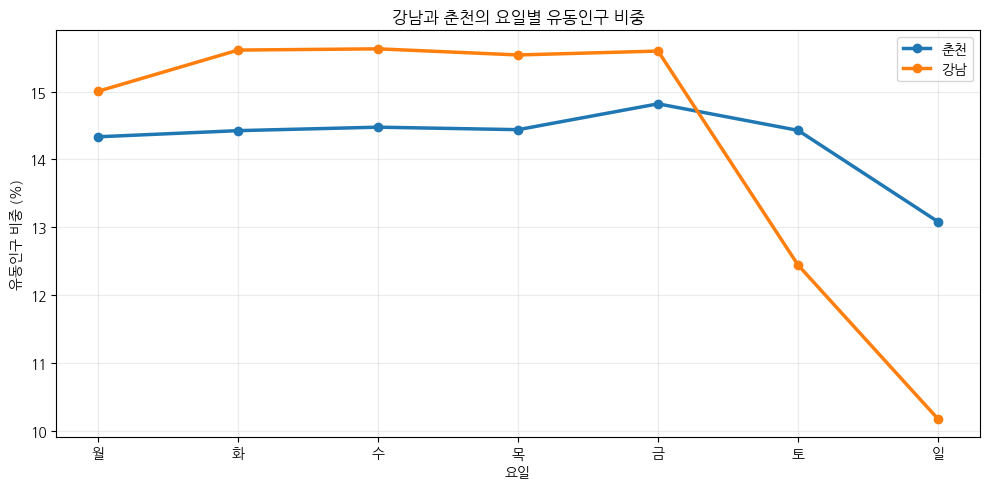

In [31]:
import matplotlib.pyplot as plt

# 1. 요일 정의
days = {
    1: '월',
    2: '화',
    3: '수',
    4: '목',
    5: '금',
    6: '토',
    7: '일'
}

# 2. 요일별 유동인구 컬럼
day_cols = [
    'FLOW_POP_CNT_MON',
    'FLOW_POP_CNT_TUS',
    'FLOW_POP_CNT_WED',
    'FLOW_POP_CNT_THU',
    'FLOW_POP_CNT_FRI',
    'FLOW_POP_CNT_SAT',
    'FLOW_POP_CNT_SUN'
]

# 3. 지역별 요일 유동인구 합계
chuncheon_day = wkdy_chuncheon[day_cols].sum()
gangnam_day = wkdy_gangnam[day_cols].sum()

# 4. 전체 요일 유동인구에서 각 요일이 차지하는 비중(%)
chuncheon_day_pct = chuncheon_day / chuncheon_day.sum() * 100
gangnam_day_pct = gangnam_day / gangnam_day.sum() * 100

# 5. 그래프
plt.figure(figsize=(10, 5))

plt.plot(
    list(days.values()),
    chuncheon_day_pct.values,
    marker='o',
    linewidth=2.5,
    label='춘천'
)

plt.plot(
    list(days.values()),
    gangnam_day_pct.values,
    marker='o',
    linewidth=2.5,
    label='강남'
)

plt.xlabel('요일')
plt.ylabel('유동인구 비중 (%)')
plt.title('강남과 춘천의 요일별 유동인구 비중')

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

연령대 컬럼: ['MAN_FLOW_POP_CNT_10G', 'MAN_FLOW_POP_CNT_20G', 'MAN_FLOW_POP_CNT_30G', 'MAN_FLOW_POP_CNT_40G', 'MAN_FLOW_POP_CNT_50G', 'MAN_FLOW_POP_CNT_60GU']


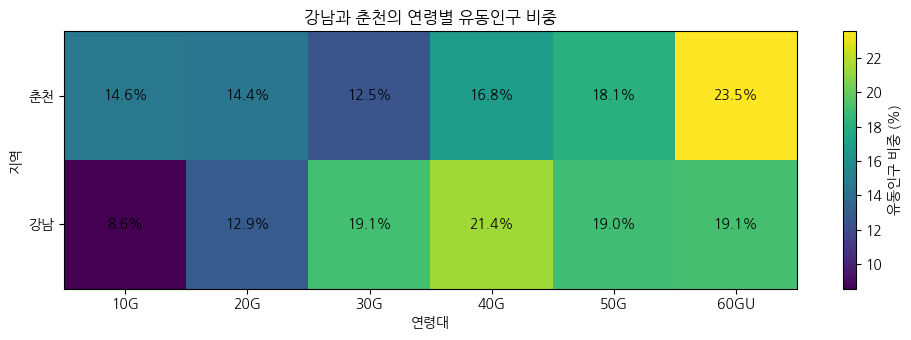

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------
# 1. 연령대별 컬럼 확인
# -----------------------------------------

age_cols = [
    col for col in age_chuncheon.columns
    if col.startswith('MAN_FLOW_POP_CNT_')
]

print("연령대 컬럼:", age_cols)

# -----------------------------------------
# 2. 연령대별 유동인구 합계 계산
# -----------------------------------------

chuncheon_age = age_chuncheon[age_cols].sum()
gangnam_age = age_gangnam[age_cols].sum()

# -----------------------------------------
# 3. 전체 유동인구 중 연령대별 비중(%)
# -----------------------------------------

chuncheon_age_pct = chuncheon_age / chuncheon_age.sum() * 100
gangnam_age_pct = gangnam_age / gangnam_age.sum() * 100

# -----------------------------------------
# 4. 연령대 이름 정리
# -----------------------------------------

age_labels = [
    col.replace('MAN_FLOW_POP_CNT_', '')
    for col in age_cols
]

# -----------------------------------------
# 5. 히트맵 데이터 구성
# -----------------------------------------

age_data = np.array([
    chuncheon_age_pct.values,
    gangnam_age_pct.values
])

plt.figure(figsize=(10, 3.5))

plt.imshow(
    age_data,
    aspect='auto'
)

plt.xticks(
    range(len(age_labels)),
    age_labels
)

plt.yticks(
    [0, 1],
    ['춘천', '강남']
)

plt.xlabel('연령대')
plt.ylabel('지역')
plt.title('강남과 춘천의 연령별 유동인구 비중')

# 각 칸에 실제 수치 표시
for i in range(2):
    for j in range(len(age_labels)):
        plt.text(
            j,
            i,
            f'{age_data[i, j]:.1f}%',
            ha='center',
            va='center'
        )

plt.colorbar(label='유동인구 비중 (%)')

plt.tight_layout()
plt.show()

춘천 시간대 컬럼: 24
강남 시간대 컬럼: 24


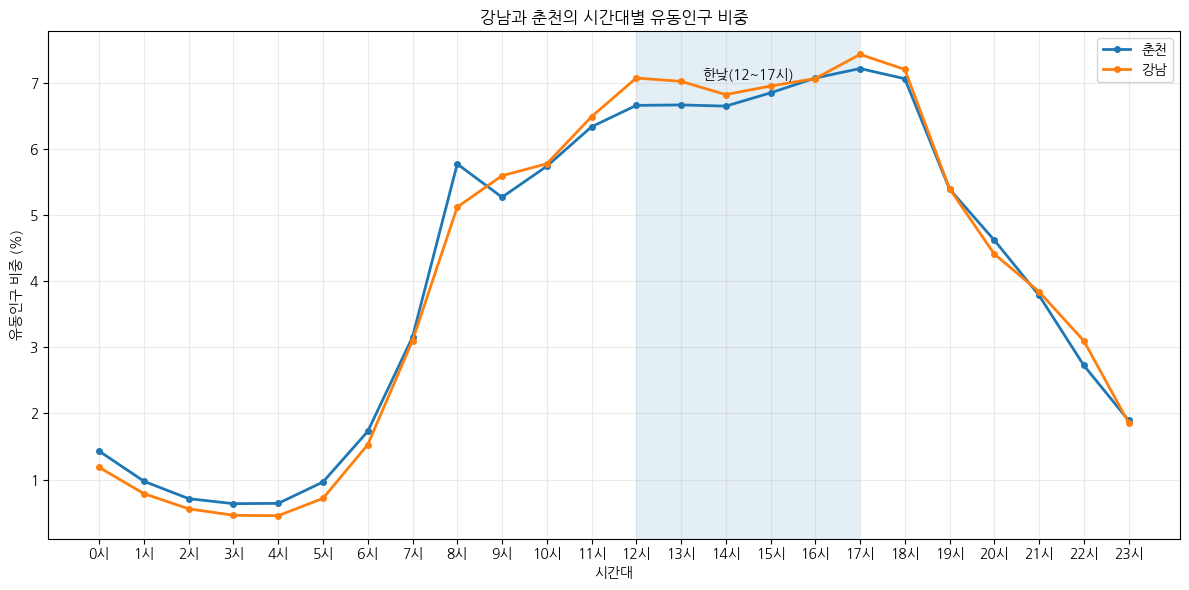

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------
# 1. 시간대 컬럼 확인
# -----------------------------------

# TMST_00 ~ TMST_23 형태의 컬럼만 찾기
time_cols_ch = [
    col for col in time_chuncheon.columns
    if col.startswith('TMST_')
]

time_cols_gn = [
    col for col in time_gangnam.columns
    if col.startswith('TMST_')
]

# 시간 순서대로 정렬
time_cols_ch = sorted(time_cols_ch)
time_cols_gn = sorted(time_cols_gn)

print("춘천 시간대 컬럼:", len(time_cols_ch))
print("강남 시간대 컬럼:", len(time_cols_gn))


# -----------------------------------
# 2. 시간대별 전체 유동인구 계산
# -----------------------------------

chuncheon_time = time_chuncheon[time_cols_ch].sum()
gangnam_time = time_gangnam[time_cols_gn].sum()


# -----------------------------------
# 3. 전체 중 각 시간대가 차지하는 비중(%)
# -----------------------------------

chuncheon_time_pct = (
    chuncheon_time / chuncheon_time.sum() * 100
)

gangnam_time_pct = (
    gangnam_time / gangnam_time.sum() * 100
)


# -----------------------------------
# 4. 시간 숫자 추출
# -----------------------------------

hours_ch = [
    int(col.split('_')[1])
    for col in time_cols_ch
]

hours_gn = [
    int(col.split('_')[1])
    for col in time_cols_gn
]


# -----------------------------------
# 5. 그래프
# -----------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    hours_ch,
    chuncheon_time_pct.values,
    marker='o',
    markersize=4,
    linewidth=2,
    label='춘천'
)

plt.plot(
    hours_gn,
    gangnam_time_pct.values,
    marker='o',
    markersize=4,
    linewidth=2,
    label='강남'
)


# X축
plt.xticks(
    range(24),
    [f'{i}시' for i in range(24)]
)

plt.xlabel('시간대')
plt.ylabel('유동인구 비중 (%)')

plt.title('강남과 춘천의 시간대별 유동인구 비중')

plt.legend()
plt.grid(alpha=0.25)


# -----------------------------------
# 6. 12~17시 한낮 구간 표시
# -----------------------------------

plt.axvspan(
    12,
    17,
    alpha=0.12
)

plt.text(
    14.5,
    max(
        chuncheon_time_pct.max(),
        gangnam_time_pct.max()
    ) * 0.95,
    '한낮(12~17시)',
    ha='center'
)

plt.tight_layout()
plt.show()

춘천 주말 유동인구 비중: 27.51%
강남 주말 유동인구 비중: 22.61%


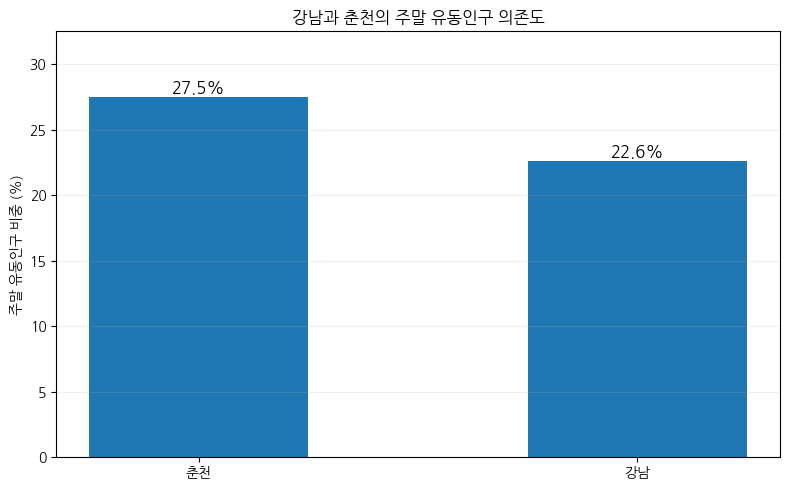

In [34]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------------
# 1. 토요일 / 일요일 유동인구
# -----------------------------------------

chuncheon_sat = wkdy_chuncheon['FLOW_POP_CNT_SAT'].sum()
chuncheon_sun = wkdy_chuncheon['FLOW_POP_CNT_SUN'].sum()

gangnam_sat = wkdy_gangnam['FLOW_POP_CNT_SAT'].sum()
gangnam_sun = wkdy_gangnam['FLOW_POP_CNT_SUN'].sum()


# -----------------------------------------
# 2. 전체 요일 유동인구
# -----------------------------------------

day_cols = [
    'FLOW_POP_CNT_MON',
    'FLOW_POP_CNT_TUS',
    'FLOW_POP_CNT_WED',
    'FLOW_POP_CNT_THU',
    'FLOW_POP_CNT_FRI',
    'FLOW_POP_CNT_SAT',
    'FLOW_POP_CNT_SUN'
]

chuncheon_total = wkdy_chuncheon[day_cols].sum().sum()
gangnam_total = wkdy_gangnam[day_cols].sum().sum()


# -----------------------------------------
# 3. 주말 의존도 계산
# -----------------------------------------

chuncheon_weekend = (
    (chuncheon_sat + chuncheon_sun)
    / chuncheon_total
    * 100
)

gangnam_weekend = (
    (gangnam_sat + gangnam_sun)
    / gangnam_total
    * 100
)


print(f'춘천 주말 유동인구 비중: {chuncheon_weekend:.2f}%')
print(f'강남 주말 유동인구 비중: {gangnam_weekend:.2f}%')


# -----------------------------------------
# 4. 그래프
# -----------------------------------------

regions = ['춘천', '강남']
values = [chuncheon_weekend, gangnam_weekend]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    regions,
    values,
    width=0.5
)

plt.ylabel('주말 유동인구 비중 (%)')
plt.title('강남과 춘천의 주말 유동인구 의존도')

# 막대 위에 실제 수치 표시
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        f'{value:.1f}%',
        ha='center',
        fontsize=12
    )

plt.ylim(0, max(values) + 5)
plt.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()